# Appliance energy use forecasting

I am predicting how much energy a home's appliances draw (in Wh) from indoor sensor readings, outdoor weather, and the time of day. The data is the UCI Appliances Energy Prediction set: about 19,700 readings taken every 10 minutes over roughly 4.5 months from a single house in Belgium.

The thing I care about here is treating it as a time series. The raw columns are just sensor snapshots. The interesting signal is in *when* the reading happened and what energy use looked like a few minutes ago. So I engineer time features and lag features, then compare a plain linear model against gradient boosting using a time based split.

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Let the notebook import the src package whether it runs from the root
# or from inside a tool.
sys.path.insert(0, os.path.abspath('.'))
from src import features as F

FIG_DIR = 'figures'
MODEL_DIR = 'model'
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42

## Load the data

I parse the timestamp into a real datetime and sort by time. Sorting matters because every lag feature later depends on rows being in order.

In [2]:
df = F.load_raw('data/energydata_complete.csv')
print('shape:', df.shape)
print('date range:', df['date'].min(), 'to', df['date'].max())
df[['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T_out']].head()

shape: (19735, 29)
date range: 2016-01-11 17:00:00 to 2016-05-27 18:00:00


,date,Appliances,lights,T1,RH_1,T_out
0,2016-01-11 17:00:00,60,30,19.89,47.596667,6.600000
1,2016-01-11 17:10:00,60,30,19.89,46.693333,6.483333
2,2016-01-11 17:20:00,50,30,19.89,46.300000,6.366667
3,2016-01-11 17:30:00,50,40,19.89,46.066667,6.250000
4,2016-01-11 17:40:00,60,40,19.89,46.333333,6.133333


## A first look at the target

Appliance energy use is spiky. Most of the time the house sits at a low baseline, then jumps when someone cooks, does laundry, or runs something heavy. That long right tail is worth knowing about, it means average error will be dominated by how well the model handles the spikes.

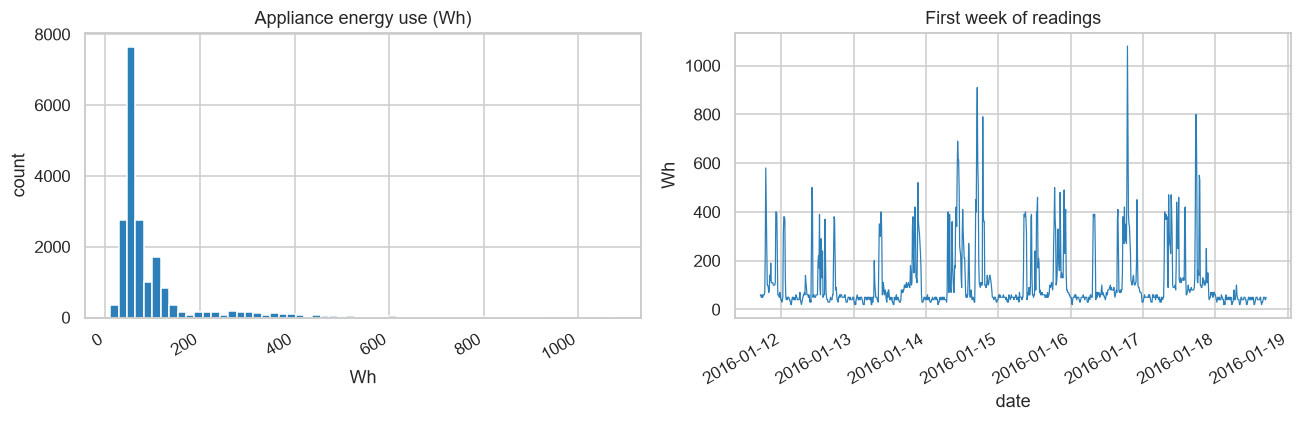

count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['Appliances'], bins=60, color='#2c7fb8')
axes[0].set_title('Appliance energy use (Wh)')
axes[0].set_xlabel('Wh')
axes[0].set_ylabel('count')

# One week of the raw series so the daily rhythm is visible.
week = df[df['date'] < df['date'].min() + pd.Timedelta(days=7)]
axes[1].plot(week['date'], week['Appliances'], linewidth=0.8, color='#2c7fb8')
axes[1].set_title('First week of readings')
axes[1].set_xlabel('date')
axes[1].set_ylabel('Wh')
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'target_overview.png'), bbox_inches='tight')
plt.show()

print(df['Appliances'].describe())

## Feature engineering

This is the core of the project. I build three kinds of features:

- **Time features** from the timestamp: hour of day, day of week, a weekend flag, and month. These capture the daily and weekly pattern of when people are home and using things.
- **Lag features** of the target: the reading 10 minutes ago, the reading one hour ago, and a rolling mean of the last hour. Energy use is sticky, so recent history is a strong predictor.
- The **sensor and weather columns** that come with the data. I drop rv1 and rv2, which are two random noise columns the authors added as a control.

All of this lives in `src/features.py` so the app and the tests use the exact same code.

In [4]:
feat = F.build_features(df)
cols = F.feature_columns()
print('rows after lag dropna:', len(feat))
print('number of features:', len(cols))
feat[['date', 'Appliances'] + F.TIME_COLUMNS + F.LAG_COLUMNS].head()

rows after lag dropna: 19729
number of features: 32


,date,Appliances,hour,dayofweek,is_weekend,month,Appliances_lag_1,Appliances_lag_6,Appliances_roll_mean_6
0,2016-01-11 18:00:00,60,18,0,0,1,50.0,60.0,55.000000
1,2016-01-11 18:10:00,60,18,0,0,1,60.0,60.0,55.000000
2,2016-01-11 18:20:00,60,18,0,0,1,60.0,50.0,55.000000
3,2016-01-11 18:30:00,70,18,0,0,1,60.0,50.0,56.666667
4,2016-01-11 18:40:00,230,18,0,0,1,70.0,60.0,60.000000


## Why a time based split

A random train/test split would let the model train on readings that come after the ones it is tested on. For a time series that is cheating: in the real world you never get to see the future. So I train on the first 80 percent of the timeline and test on the last 20 percent, kept in order. The scores below are lower than a random split would give, and that is the point, they are honest.

In [5]:
train, test = F.time_based_split(feat, train_frac=0.8)
X_train, y_train = train[cols], train[F.TARGET]
X_test, y_test = test[cols], test[F.TARGET]
print('train rows:', len(train), '| test rows:', len(test))
print('train ends:', train['date'].max())
print('test starts:', test['date'].min())

train rows: 15783 | test rows: 3946
train ends: 2016-04-30 08:20:00
test starts: 2016-04-30 08:30:00


## Correlation with the target

A quick scan of which features move with appliance use. The lag features stand out, which is the expected result and a good sign the time series framing is pulling its weight.

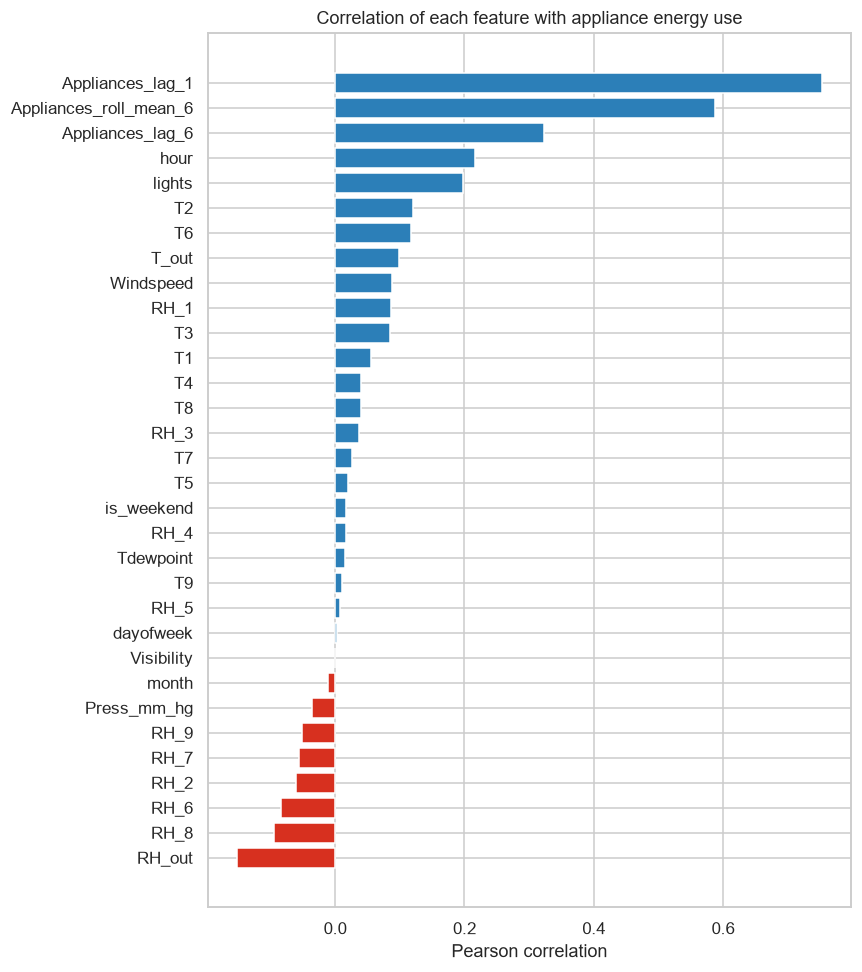

In [6]:
corr = feat[cols + [F.TARGET]].corr()[F.TARGET].drop(F.TARGET).sort_values()
fig, ax = plt.subplots(figsize=(8, 9))
colors = ['#d7301f' if v < 0 else '#2c7fb8' for v in corr.values]
ax.barh(corr.index, corr.values, color=colors)
ax.set_title('Correlation of each feature with appliance energy use')
ax.set_xlabel('Pearson correlation')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'feature_correlation.png'), bbox_inches='tight')
plt.show()

## Baseline: linear regression

I start with a plain linear model. It is fast, it is a fair baseline, and if a heavier model cannot beat it then the heavier model is not worth the cost.

In [7]:
def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    rmse = float(np.sqrt(mean_squared_error(y_te, pred)))
    mae = float(mean_absolute_error(y_te, pred))
    r2 = float(r2_score(y_te, pred))
    print(f'{name:>22}:  RMSE={rmse:7.2f}  MAE={mae:7.2f}  R2={r2:6.3f}')
    return {'name': name, 'rmse': rmse, 'mae': mae, 'r2': r2, 'pred': pred}

results = []
lin = LinearRegression()
results.append(evaluate('Linear regression', lin, X_train, y_train, X_test, y_test))

     Linear regression:  RMSE=  61.67  MAE=  28.11  R2= 0.540


## Gradient boosting

Histogram gradient boosting. In theory it can catch the non linear interactions between time of day, weather, and recent use that the linear model cannot. I keep it shallow and use early stopping so it does not just memorize the training spikes. I tried deeper and faster settings too and they all did worse on the held out period, so shallow and slow it is.

In [8]:
hgb = HistGradientBoostingRegressor(
    max_iter=500,
    learning_rate=0.03,
    max_depth=3,
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20,
    random_state=RANDOM_STATE,
)
results.append(evaluate('Gradient boosting', hgb, X_train, y_train, X_test, y_test))

     Gradient boosting:  RMSE=  64.06  MAE=  37.94  R2= 0.504


## Results side by side

Here is the honest surprise of this project: the linear baseline wins. On a time based split the lag features do most of the work and their relationship to the target is close to linear, so the extra flexibility of gradient boosting mostly buys it a chance to overfit. I would rather report this than quietly swap in a fancier model that does worse. I pick whichever model has the lower RMSE as the one to ship.

In [9]:
summary = pd.DataFrame([{k: r[k] for k in ('name', 'rmse', 'mae', 'r2')} for r in results])
summary = summary.set_index('name').round(3)
best = min(results, key=lambda r: r['rmse'])
best_model = lin if best['name'] == 'Linear regression' else hgb
print('best model by RMSE:', best['name'])
summary

best model by RMSE: Linear regression


,rmse,mae,r2
name,,,
Linear regression,61.674,28.111,0.540
Gradient boosting,64.056,37.941,0.504


## Feature importance

Permutation importance on the best model. I shuffle each feature one at a time and watch how much the score drops. It works on any model, not just trees, and it is honest about what the model actually leans on. The lag features dominate, which is exactly why the time series framing matters.

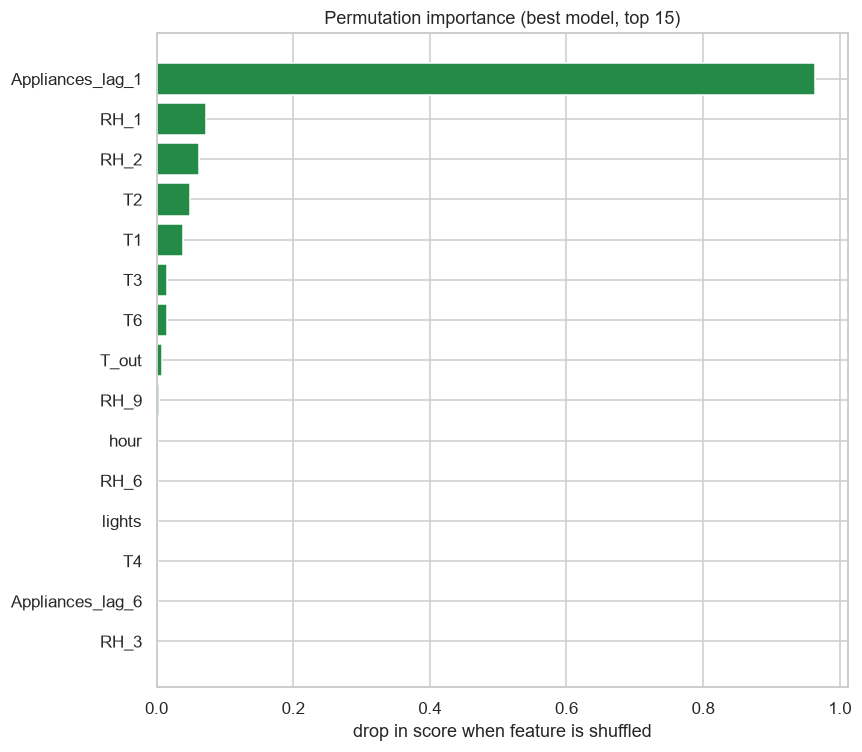

In [10]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_model, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, n_jobs=1
)
imp = pd.Series(perm.importances_mean, index=cols).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(imp.index, imp.values, color='#238b45')
ax.set_title('Permutation importance (best model, top 15)')
ax.set_xlabel('drop in score when feature is shuffled')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'feature_importance.png'), bbox_inches='tight')
plt.show()

## Actual vs predicted over time

The numbers only say so much. Here is the best model's prediction laid over the real series for a slice of the held out test period. It tracks the baseline and the timing of spikes well, and like most models on spiky data it tends to undershoot the tallest peaks.

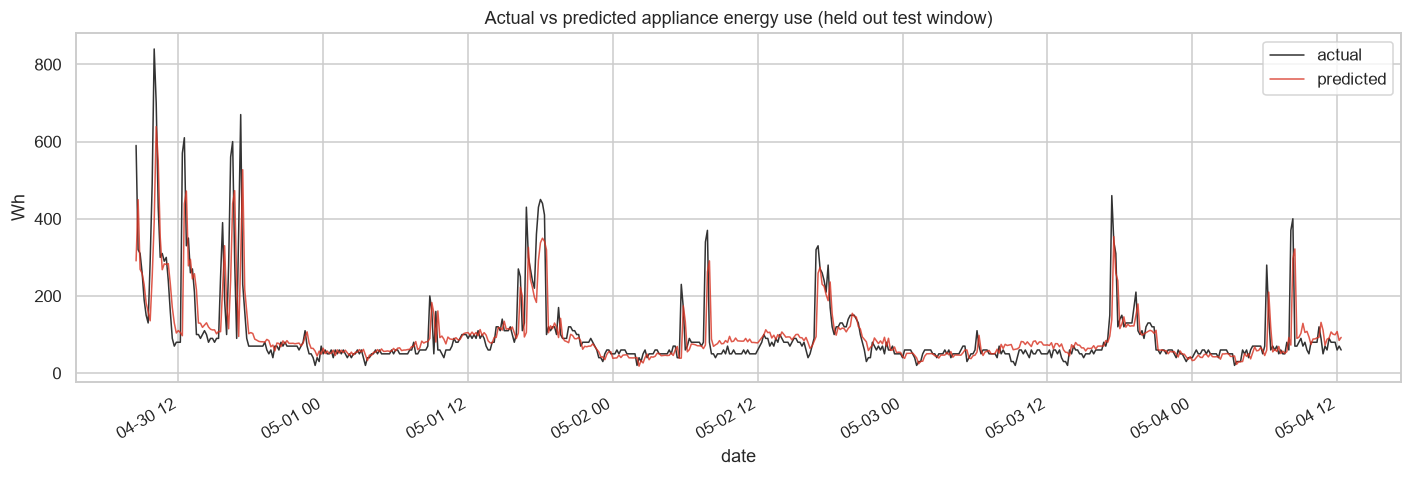

In [11]:
best_pred = best['pred']
plot_df = test[['date']].copy()
plot_df['actual'] = y_test.values
plot_df['predicted'] = best_pred
window = plot_df.iloc[:600]  # about 4 days at 10 minute spacing

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(window['date'], window['actual'], label='actual', linewidth=1.0, color='#333333')
ax.plot(window['date'], window['predicted'], label='predicted', linewidth=1.0, color='#d7301f', alpha=0.8)
ax.set_title('Actual vs predicted appliance energy use (held out test window)')
ax.set_xlabel('date')
ax.set_ylabel('Wh')
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'actual_vs_predicted.png'), bbox_inches='tight')
plt.show()

## Residuals

Residuals are actual minus predicted. I want them centered near zero with no strong pattern against the prediction. The spread widens at higher predicted values, which is the undershoot on spikes showing up again.

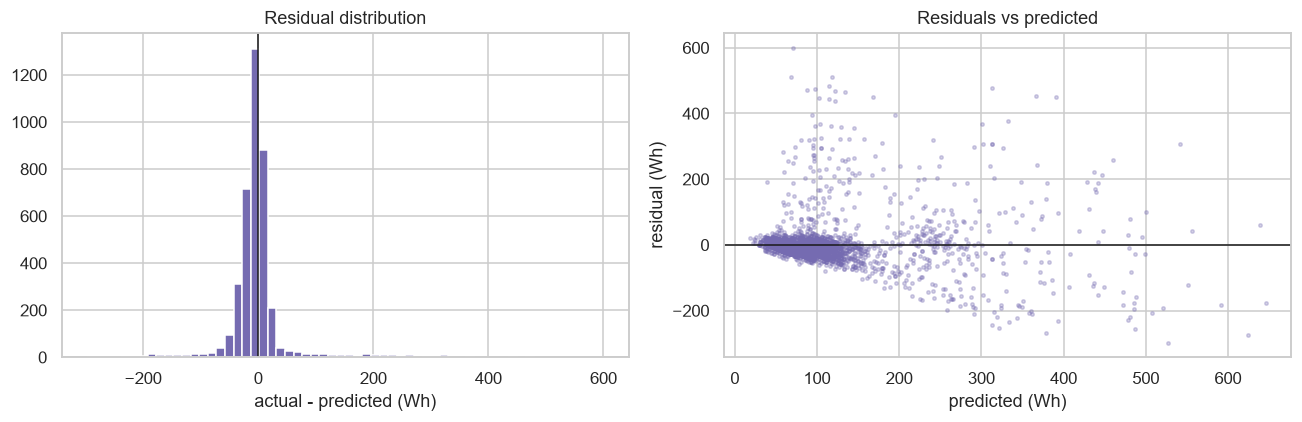

In [12]:
resid = y_test.values - best_pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(resid, bins=60, color='#756bb1')
axes[0].axvline(0, color='k', linewidth=1)
axes[0].set_title('Residual distribution')
axes[0].set_xlabel('actual - predicted (Wh)')

axes[1].scatter(best_pred, resid, s=5, alpha=0.3, color='#756bb1')
axes[1].axhline(0, color='k', linewidth=1)
axes[1].set_title('Residuals vs predicted')
axes[1].set_xlabel('predicted (Wh)')
axes[1].set_ylabel('residual (Wh)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'residuals.png'), bbox_inches='tight')
plt.show()

## Save the model

I retrain the winning model (the linear one) on the full timeline and save it as a bundle together with the ordered feature list and the training median of each feature. The app uses the medians to prefill sensible defaults so a user only has to change the few inputs they care about.

In [13]:
from sklearn.base import clone
final_model = clone(best_model)
final_model.fit(feat[cols], feat[F.TARGET])
print('shipping model:', best['name'])

bundle = {
    'model': final_model,
    'model_name': best['name'],
    'feature_columns': cols,
    'feature_medians': feat[cols].median().to_dict(),
    'metrics': {r['name']: {k: r[k] for k in ('rmse', 'mae', 'r2')} for r in results},
}
out = os.path.join(MODEL_DIR, 'energy_model.joblib')
joblib.dump(bundle, out)
print('saved', out)
print('bundle keys:', list(bundle.keys()))

shipping model: Linear regression
saved model\energy_model.joblib
bundle keys: ['model', 'model_name', 'feature_columns', 'feature_medians', 'metrics']


## What I would do next

- The spikes are the hard part. A quantile loss or a model aimed at the peaks would help if the goal were catching demand surges.
- There is only one house here, so the model learns this household's habits. It would need retraining per home.
- Longer lags and a rolling std could add a little, but I kept the feature set small on purpose so it stays easy to read and fast to serve.